# Predicting Student Exam Scores Using Backpropagation Neural Networks

## Project Overview
This project analyzes how daily study and lifestyle habits—including study duration, sleep, screen time, attendance, exercise, and mental health—influence student exam scores. Using a dataset of **1,000 student records** across **14 input features**, I built, benchmarked, and diagnosed **five progressive neural network regression scenarios** to measure the impact of feature scaling, correlation-based feature selection, and hyperparameter tuning.

## Experimental Design
All five scenarios are evaluated on the **exact same 80/20 train–test split** (`RANDOM_STATE = 42`) with strict data-leakage prevention:

| Scenario | Description | Features | Scaling | Tuning |
| :--- | :--- | :--- | :--- | :--- |
| **1. Baseline** | Default MLP (`16 → 8 → 1`, ReLU, Adam `lr=0.001`) | All encoded features | None | None |
| **2. Standardization** | Leakage-free `StandardScaler` fit on training split only | All encoded features | `StandardScaler` | None |
| **3. Feature Selection** | Top-5 predictors selected via training-set correlation | Top 5 features | None | None |
| **4. Hyperparameter Tuning** | 3-fold `GridSearchCV` over layer sizes, `lr`, and `batch_size` | All encoded features | None | `GridSearchCV` |
| **5. Combined Pipeline** | End-to-end `Pipeline` combining top-5 features, scaling, and tuning | Top 5 features | `StandardScaler` (per fold) | `GridSearchCV` |

## Tech Stack
* **Deep Learning & Tuning:** TensorFlow / Keras, SciKeras, Scikit-learn (`GridSearchCV`, `Pipeline`)
* **Data Processing & Visualization:** NumPy, Pandas, Matplotlib, Seaborn

> **How to Reproduce:** Place `student_habits_performance.csv` in the same directory as this notebook and run **Kernel → Restart & Run All**. Every metric table and diagnostic chart updates automatically from the executed models.

## 1. Environment Setup & Reproducibility

In [1]:
import os
import random
from math import sqrt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, InputLayer
from tensorflow.keras.optimizers import Adam
from scikeras.wrappers import KerasRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Global configuration for full reproducibility
RANDOM_STATE = 42
DATA_PATH = "student_habits_performance.csv"

def set_seeds(seed=RANDOM_STATE):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seeds()
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110

## 2. Data Loading & Cleaning
We drop `student_id` (a unique identifier with no predictive signal) and inspect missing values **before** applying imputation. In this dataset, missing values in `parental_education_level` represent students whose parents have no formal degree, so imputing `'None'` preserves all 1,000 samples as a meaningful category rather than dropping rows.

In [2]:
# Load raw dataset and drop identifier column
df = pd.read_csv(DATA_PATH).drop(columns=["student_id"])
print(f"Dataset shape: {df.shape[0]} rows x {df.shape[1]} columns\n")

# Audit missing values BEFORE cleaning
missing_before = df.isna().sum()
print("Missing values before cleaning:")
print(missing_before[missing_before > 0] if missing_before.any() else "None")

# Impute missing parental education level as an explicit category
df["parental_education_level"] = df["parental_education_level"].fillna("None")

print(f"\nTotal missing values after cleaning: {df.isna().sum().sum()}")
df.head()

Dataset shape: 1000 rows x 15 columns

Missing values before cleaning:
parental_education_level    91
dtype: int64

Total missing values after cleaning: 0


,age,gender,study_hours_per_day,social_media_hours,netflix_hours,part_time_job,attendance_percentage,sleep_hours,diet_quality,exercise_frequency,parental_education_level,internet_quality,mental_health_rating,extracurricular_participation,exam_score
0,23,Female,0.0,1.2,1.1,No,85.0,8.0,Fair,6,Master,Average,8,Yes,56.2
1,20,Female,6.9,2.8,2.3,No,97.3,4.6,Good,6,High School,Average,8,No,100.0
2,21,Male,1.4,3.1,1.3,No,94.8,8.0,Poor,1,High School,Poor,1,No,34.3
3,23,Female,1.0,3.9,1.0,No,71.0,9.2,Poor,4,Master,Good,1,Yes,26.8
4,19,Female,5.0,4.4,0.5,No,90.9,4.9,Fair,3,Master,Good,1,No,66.4


In [3]:
df.info()
display(df.describe().T.round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   age                            1000 non-null   int64  
 1   gender                         1000 non-null   object 
 2   study_hours_per_day            1000 non-null   float64
 3   social_media_hours             1000 non-null   float64
 4   netflix_hours                  1000 non-null   float64
 5   part_time_job                  1000 non-null   object 
 6   attendance_percentage          1000 non-null   float64
 7   sleep_hours                    1000 non-null   float64
 8   diet_quality                   1000 non-null   object 
 9   exercise_frequency             1000 non-null   int64  
 10  parental_education_level       1000 non-null   object 
 11  internet_quality               1000 non-null   object 
 12  mental_health_rating           1000 non-null   in

,count,mean,std,min,25%,50%,75%,max
age,1000.0,20.50,2.31,17.0,18.75,20.0,23.00,24.0
study_hours_per_day,1000.0,3.55,1.47,0.0,2.60,3.5,4.50,8.3
social_media_hours,1000.0,2.51,1.17,0.0,1.70,2.5,3.30,7.2
netflix_hours,1000.0,1.82,1.08,0.0,1.00,1.8,2.52,5.4
attendance_percentage,1000.0,84.13,9.40,56.0,78.00,84.4,91.02,100.0
sleep_hours,1000.0,6.47,1.23,3.2,5.60,6.5,7.30,10.0
exercise_frequency,1000.0,3.04,2.03,0.0,1.00,3.0,5.00,6.0
mental_health_rating,1000.0,5.44,2.85,1.0,3.00,5.0,8.00,10.0
exam_score,1000.0,69.60,16.89,18.4,58.48,70.5,81.32,100.0


In [4]:
# Inspect categorical feature distributions
obj_cols = df.select_dtypes(exclude="number").columns.tolist()
num_cols = df.select_dtypes(include="number").columns.difference(["exam_score"]).tolist()

print(f"Numerical features ({len(num_cols)}): {num_cols}")
print(f"Categorical features ({len(obj_cols)}): {obj_cols}\n")

for col in obj_cols:
    counts = df[col].value_counts()
    pct = (counts / len(df) * 100).round(1)
    summary = pd.DataFrame({"Count": counts, "Percentage (%)": pct})
    print(f"--- {col} ---")
    print(summary, "\n")

Numerical features (8): ['age', 'attendance_percentage', 'exercise_frequency', 'mental_health_rating', 'netflix_hours', 'sleep_hours', 'social_media_hours', 'study_hours_per_day']
Categorical features (6): ['gender', 'part_time_job', 'diet_quality', 'parental_education_level', 'internet_quality', 'extracurricular_participation']

--- gender ---
        Count  Percentage (%)
gender                       
Female    481            48.1
Male      477            47.7
Other      42             4.2 

--- part_time_job ---
               Count  Percentage (%)
part_time_job                       
No               785            78.5
Yes              215            21.5 

--- diet_quality ---
              Count  Percentage (%)
diet_quality                       
Fair            437            43.7
Good            378            37.8
Poor            185            18.5 

--- parental_education_level ---
                          Count  Percentage (%)
parental_education_level                     

## 3. Exploratory Data Analysis (EDA)

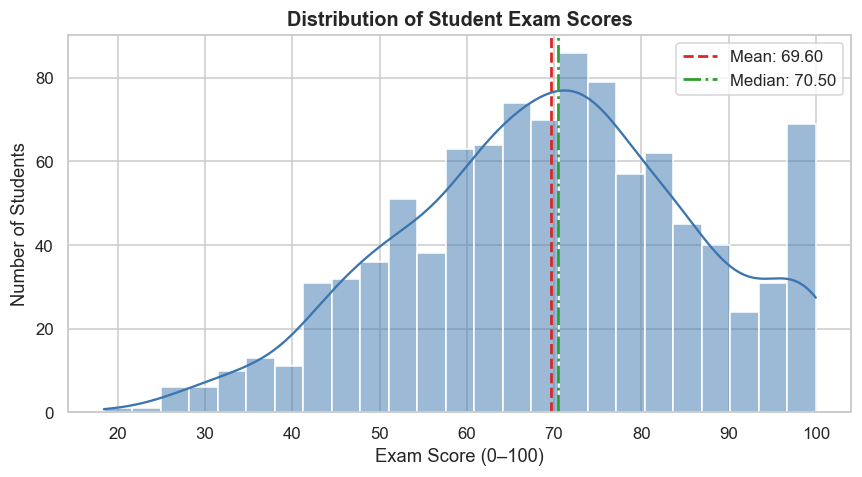

In [5]:
# Target distribution: exam_score
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.histplot(df["exam_score"], kde=True, bins=25, color="#3b75af", ax=ax)

mean_score = df["exam_score"].mean()
median_score = df["exam_score"].median()
ax.axvline(mean_score, color="#d62728", linestyle="--", linewidth=1.8, label=f"Mean: {mean_score:.2f}")
ax.axvline(median_score, color="#2ca02c", linestyle="-.", linewidth=1.8, label=f"Median: {median_score:.2f}")

ax.set_title("Distribution of Student Exam Scores", fontsize=13, fontweight="bold")
ax.set_xlabel("Exam Score (0–100)")
ax.set_ylabel("Number of Students")
ax.legend()
plt.tight_layout()
plt.show()

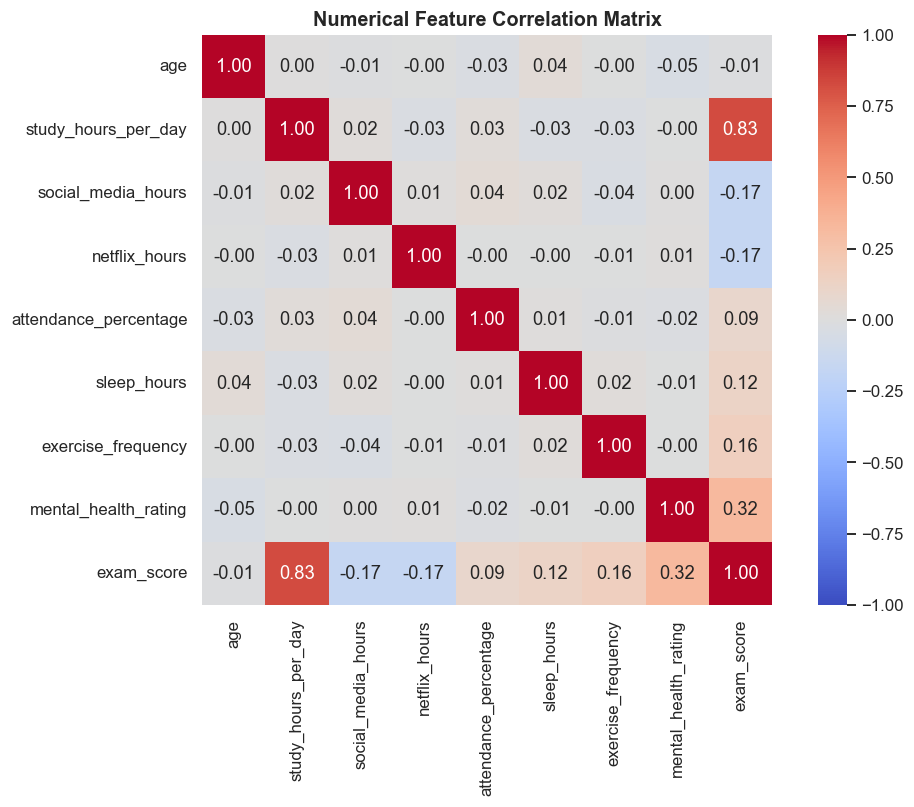

In [6]:
# Correlation matrix for numerical features
plt.figure(figsize=(10, 7.5))
corr_num = df.corr(numeric_only=True)
sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Numerical Feature Correlation Matrix", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### Key EDA Takeaways
* **Dominant Positive Driver:** `study_hours_per_day` exhibits the strongest positive correlation with `exam_score` ($r \approx 0.83$), followed by `mental_health_rating` ($r \approx 0.32$) and `exercise_frequency` ($r \approx 0.16$).
* **Negative Distraction Signals:** `netflix_hours` ($r \approx -0.17$) and `social_media_hours` ($r \approx -0.17$) correlate negatively with exam performance.
* **Target Properties:** `exam_score` is approximately bell-shaped around a mean of **69.60** (median **70.50**, std **16.89**), with scores bounded at a hard ceiling of **100.0**.
* **Scale Disparity:** Numerical inputs span very different magnitudes—for example, `attendance_percentage` ranges from **56.0 to 100.0**, whereas `study_hours_per_day` ranges from **0.0 to 8.3**—motivating feature standardization for gradient-based neural network training.

## 4. Feature Encoding & Shared Evaluation Utilities
We apply single-pass one-hot encoding (`drop_first=True`, integer dtype) to convert the 6 categorical features into binary numeric indicators without dummy-variable multicollinearity. We then create **one shared 80/20 train–test split** and reusable modeling/evaluation functions so every scenario is compared fairly on the exact same 200 test students.

Encoded dataset shape: 1000 rows x 20 columns


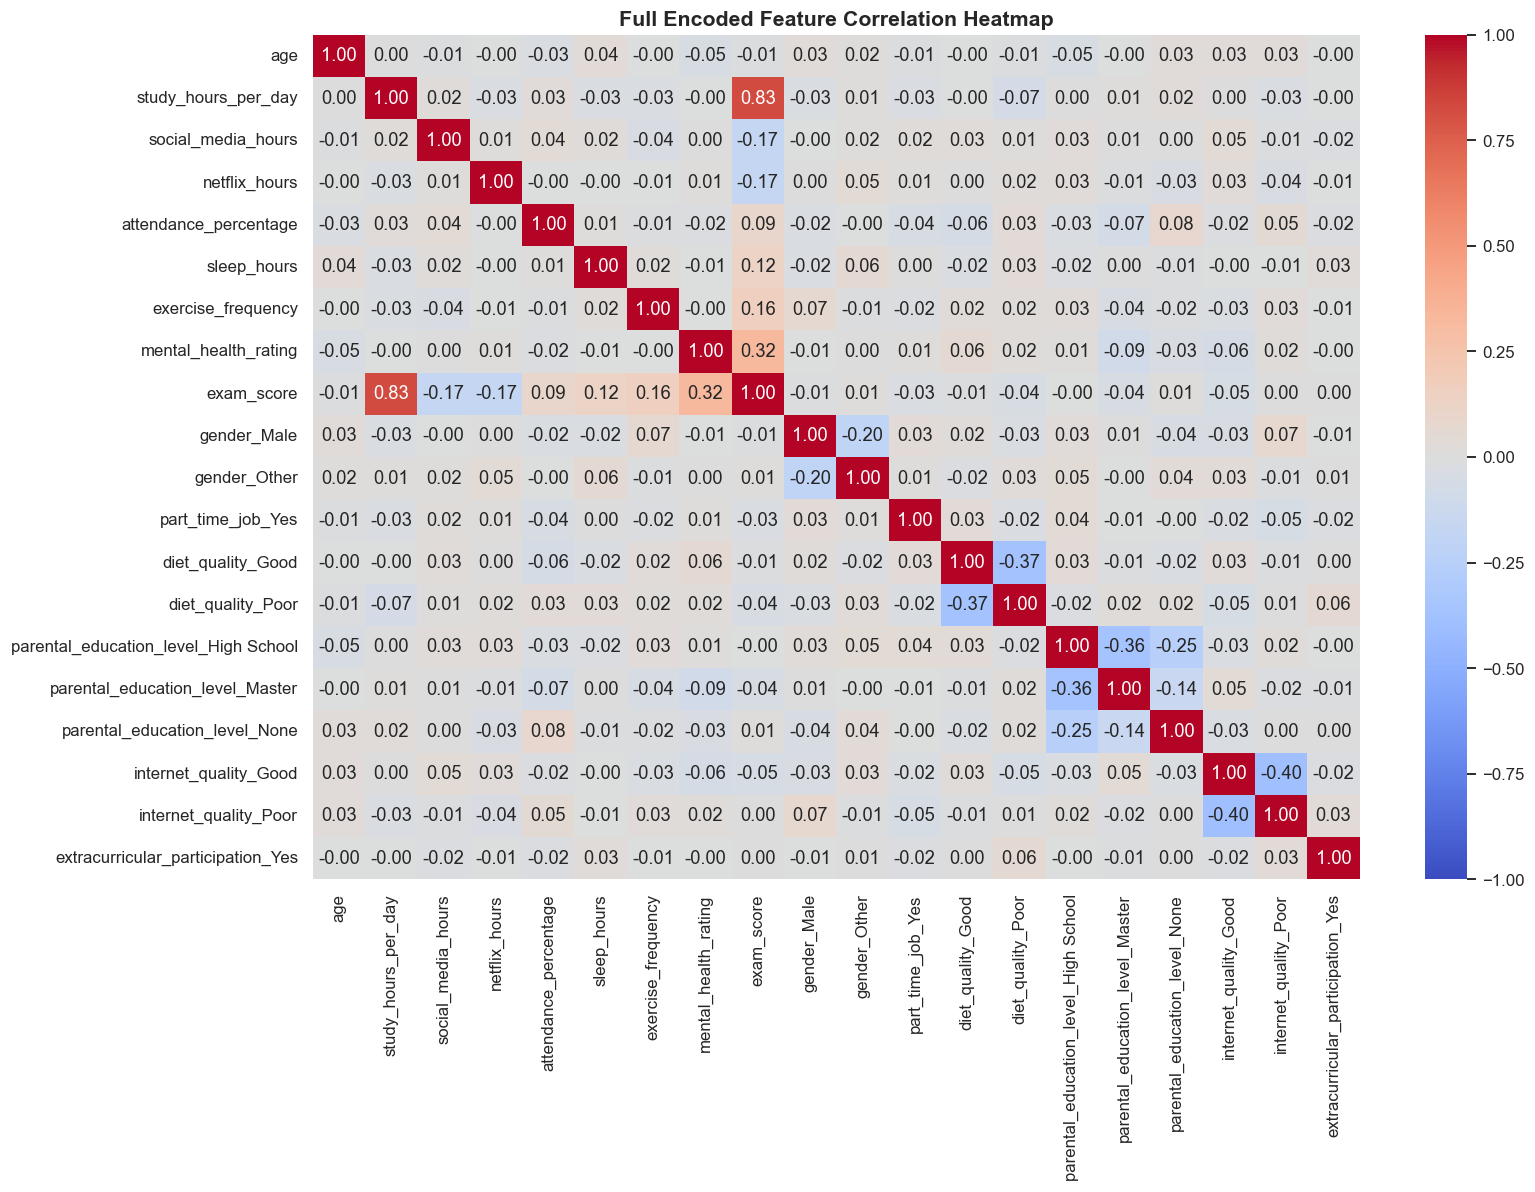

In [7]:
# Single-pass one-hot encoding with clean integer dtype
df_encoded = pd.get_dummies(df, columns=obj_cols, drop_first=True, dtype=int)
print(f"Encoded dataset shape: {df_encoded.shape[0]} rows x {df_encoded.shape[1]} columns")

# Full encoded correlation heatmap
plt.figure(figsize=(15, 11))
sns.heatmap(df_encoded.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Full Encoded Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [8]:
# Shared 80/20 train-test split across ALL 5 scenarios (fair apples-to-apples benchmark)
X_full = df_encoded.drop(columns=["exam_score"])
y_full = df_encoded["exam_score"].values.astype("float32")

X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y_full, test_size=0.2, random_state=RANDOM_STATE
)
print(f"Training set: {X_train_full.shape[0]} samples | Test set: {X_test_full.shape[0]} samples")

# Containers for systematic tracking across all scenarios
results_log = []
predictions_log = {}
histories_log = {}

def build_mlp(input_dim, units1=16, units2=8, learning_rate=0.001):
    model = Sequential([
        InputLayer(shape=(input_dim,)),
        Dense(units1, activation="relu"),
        Dense(units2, activation="relu"),
        Dense(1),
    ])
    model.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss="mean_squared_error",
        metrics=["mae"],
    )
    return model

def log_evaluation(scenario_name, y_true, y_pred, notes=""):
    y_pred_flat = np.asarray(y_pred).ravel()
    rmse = sqrt(mean_squared_error(y_true, y_pred_flat))
    mae = mean_absolute_error(y_true, y_pred_flat)
    r2 = r2_score(y_true, y_pred_flat)

    results_log.append({
        "Scenario": scenario_name,
        "RMSE": round(rmse, 4),
        "MAE": round(mae, 4),
        "R2": round(r2, 4),
        "Notes": notes,
    })
    predictions_log[scenario_name] = y_pred_flat

    print(f"=== {scenario_name} ===")
    print(f"RMSE     : {rmse:.2f} points")
    print(f"MAE      : {mae:.2f} points")
    print(f"R² Score : {r2:.4f}")

Training set: 800 samples | Test set: 200 samples


## 5. Experimental Scenarios

### Scenario 1: Baseline MLP (Unscaled Full Feature Set)
**Hypothesis:** Establish a baseline regression benchmark using all encoded features with a compact two-hidden-layer backpropagation network (`16 → 8 → 1`, ReLU activations, Adam `lr=0.001`, 100 epochs, `batch_size=16`).

In [9]:
set_seeds()

model_s1 = build_mlp(input_dim=X_train_full.shape[1], units1=16, units2=8, learning_rate=0.001)
history_s1 = model_s1.fit(
    X_train_full, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=0,
)

y_pred_s1 = model_s1.predict(X_test_full, verbose=0)
histories_log["1. Baseline"] = history_s1.history
log_evaluation("1. Baseline", y_test, y_pred_s1, notes="All encoded features, unscaled, default MLP")

=== 1. Baseline ===
RMSE     : 5.17 points
MAE      : 4.18 points
R² Score : 0.8959


### Scenario 2: Feature Standardization (`StandardScaler`)
**Hypothesis:** Standardizing features to zero mean and unit variance should smooth the loss surface for Adam backpropagation. To prevent **data leakage**, `StandardScaler` is fitted strictly on `X_train_full` and then applied to `X_test_full`.

In [10]:
set_seeds()

# Fit scaler strictly on training data to prevent data leakage
scaler_s2 = StandardScaler()
X_train_scaled = scaler_s2.fit_transform(X_train_full)
X_test_scaled = scaler_s2.transform(X_test_full)

model_s2 = build_mlp(input_dim=X_train_scaled.shape[1], units1=16, units2=8, learning_rate=0.001)
history_s2 = model_s2.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=0,
)

y_pred_s2 = model_s2.predict(X_test_scaled, verbose=0)
histories_log["2. Standardization"] = history_s2.history
log_evaluation("2. Standardization", y_test, y_pred_s2, notes="All encoded features + StandardScaler (train-fit only)")

=== 2. Standardization ===
RMSE     : 7.09 points
MAE      : 5.78 points
R² Score : 0.8038


### Scenario 3: Correlation-Based Feature Selection (Top 5 Predictors)
**Hypothesis:** Filtering out weakly correlated predictors and training only on the top 5 features may reduce variance and model complexity. Correlations are computed strictly on the **training split** to ensure zero test-set leakage.

In [11]:
# Select top 5 features using training data ONLY
train_with_target = X_train_full.copy()
train_with_target["exam_score"] = y_train

train_corr = train_with_target.corr()["exam_score"].abs().sort_values(ascending=False)
top5_features = train_corr.index[1:6].tolist()

print("Top 5 features selected from training split:")
print(train_corr[1:6].round(4), "\n")

X_train_sel = X_train_full[top5_features]
X_test_sel = X_test_full[top5_features]

set_seeds()

model_s3 = build_mlp(input_dim=X_train_sel.shape[1], units1=16, units2=8, learning_rate=0.001)
history_s3 = model_s3.fit(
    X_train_sel, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=0,
)

y_pred_s3 = model_s3.predict(X_test_sel, verbose=0)
histories_log["3. Feature Selection"] = history_s3.history
log_evaluation("3. Feature Selection", y_test, y_pred_s3, notes=f"Top 5 features: {', '.join(top5_features)}")

Top 5 features selected from training split:
study_hours_per_day     0.8270
mental_health_rating    0.3286
social_media_hours      0.1927
netflix_hours           0.1669
exercise_frequency      0.1466
Name: exam_score, dtype: float64 

=== 3. Feature Selection ===
RMSE     : 5.94 points
MAE      : 4.89 points
R² Score : 0.8624


### Scenario 4: Hyperparameter Tuning (`GridSearchCV` + `SciKeras`)
**Hypothesis:** Systematically searching hidden-layer widths (`units1`, `units2`), Adam `learning_rate`, and `batch_size` using 3-fold cross-validation (`scoring='neg_mean_absolute_error'`) can identify a better-performing network configuration on the full feature set.

In [12]:
set_seeds()

regressor_s4 = KerasRegressor(
    model=build_mlp,
    model__input_dim=X_train_full.shape[1],
    verbose=0,
)

param_grid_s4 = {
    "model__units1": [8, 16, 32],
    "model__units2": [4, 8, 16],
    "model__learning_rate": [0.001, 0.01],
    "batch_size": [16, 32],
    "epochs": [50],
}

# Note: If TensorFlow multiprocessing slows down on Windows, set n_jobs=1
grid_s4 = GridSearchCV(
    estimator=regressor_s4,
    param_grid=param_grid_s4,
    scoring="neg_mean_absolute_error",
    cv=3,
    n_jobs=-1,
)

grid_s4.fit(X_train_full, y_train)
y_pred_s4 = grid_s4.best_estimator_.predict(X_test_full)

print("Best Parameters (Scenario 4):", grid_s4.best_params_)
log_evaluation("4. Hyperparameter Tuning", y_test, y_pred_s4, notes=f"Best CV params: {grid_s4.best_params_}")

Best Parameters (Scenario 4): {'batch_size': 32, 'epochs': 50, 'model__learning_rate': 0.01, 'model__units1': 32, 'model__units2': 4}
=== 4. Hyperparameter Tuning ===
RMSE     : 5.23 points
MAE      : 4.23 points
R² Score : 0.8935


### Scenario 5: Combined Optimization Pipeline (Feature Selection + Standardization + Tuning)
**Hypothesis:** Combining top-5 feature selection, fold-safe `StandardScaler` inside a scikit-learn `Pipeline`, and `GridSearchCV` hyperparameter tuning tests whether stacking all three strategies produces the strongest generalization. Wrapping `StandardScaler` inside `Pipeline` guarantees scaling is fitted independently on each cross-validation fold (zero leakage) and consistently applied at inference time.

In [13]:
set_seeds()

pipeline_s5 = Pipeline([
    ("scaler", StandardScaler()),
    ("reg", KerasRegressor(
        model=build_mlp,
        model__input_dim=X_train_sel.shape[1],
        verbose=0,
    )),
])

param_grid_s5 = {
    "reg__model__units1": [8, 16, 32],
    "reg__model__units2": [4, 8, 16],
    "reg__model__learning_rate": [0.001, 0.01],
    "reg__batch_size": [16, 32],
    "reg__epochs": [50],
}

# Note: If TensorFlow multiprocessing slows down on Windows, set n_jobs=1
grid_s5 = GridSearchCV(
    estimator=pipeline_s5,
    param_grid=param_grid_s5,
    scoring="neg_mean_absolute_error",
    cv=3,
    n_jobs=-1,
)

grid_s5.fit(X_train_sel, y_train)
y_pred_s5 = grid_s5.best_estimator_.predict(X_test_sel)

print("Best Parameters (Scenario 5):", grid_s5.best_params_)
log_evaluation("5. Combined Pipeline", y_test, y_pred_s5, notes=f"Top 5 + StandardScaler + GridSearchCV")

Best Parameters (Scenario 5): {'reg__batch_size': 16, 'reg__epochs': 50, 'reg__model__learning_rate': 0.01, 'reg__model__units1': 8, 'reg__model__units2': 16}
=== 5. Combined Pipeline ===
RMSE     : 6.06 points
MAE      : 4.88 points
R² Score : 0.8568


## 6. Model Comparison & Diagnostic Visualizations

In [14]:
# Dynamic summary table across all 5 scenarios + cross-scenario average
results_df = pd.DataFrame(results_log)

avg_row = pd.DataFrame([{
    "Scenario": "Average (All 5 Scenarios)",
    "RMSE": round(results_df["RMSE"].mean(), 4),
    "MAE": round(results_df["MAE"].mean(), 4),
    "R2": round(results_df["R2"].mean(), 4),
    "Notes": "Mean across all 5 controlled experiments",
}])

summary_table = pd.concat([results_df, avg_row], ignore_index=True)
display(summary_table[["Scenario", "RMSE", "MAE", "R2", "Notes"]])

best_idx = results_df["RMSE"].idxmin()
best_scenario_name = results_df.loc[best_idx, "Scenario"]
print(
    f"\nBest Performing Scenario: {best_scenario_name} "
    f"(RMSE: {results_df.loc[best_idx, 'RMSE']:.2f}, "
    f"MAE: {results_df.loc[best_idx, 'MAE']:.2f}, "
    f"R²: {results_df.loc[best_idx, 'R2']:.4f})"
)

,Scenario,RMSE,MAE,R2,Notes
0,1. Baseline,5.1677,4.1844,0.8959,"All encoded features, unscaled, default MLP"
1,2. Standardization,7.0936,5.7799,0.8038,All encoded features + StandardScaler (train-f...
2,3. Feature Selection,5.9393,4.8914,0.8624,"Top 5 features: study_hours_per_day, mental_he..."
3,4. Hyperparameter Tuning,5.2266,4.2309,0.8935,"Best CV params: {'batch_size': 32, 'epochs': 5..."
4,5. Combined Pipeline,6.0589,4.8797,0.8568,Top 5 + StandardScaler + GridSearchCV
5,Average (All 5 Scenarios),5.8972,4.7933,0.8625,Mean across all 5 controlled experiments



Best Performing Scenario: 1. Baseline (RMSE: 5.17, MAE: 4.18, R²: 0.8959)


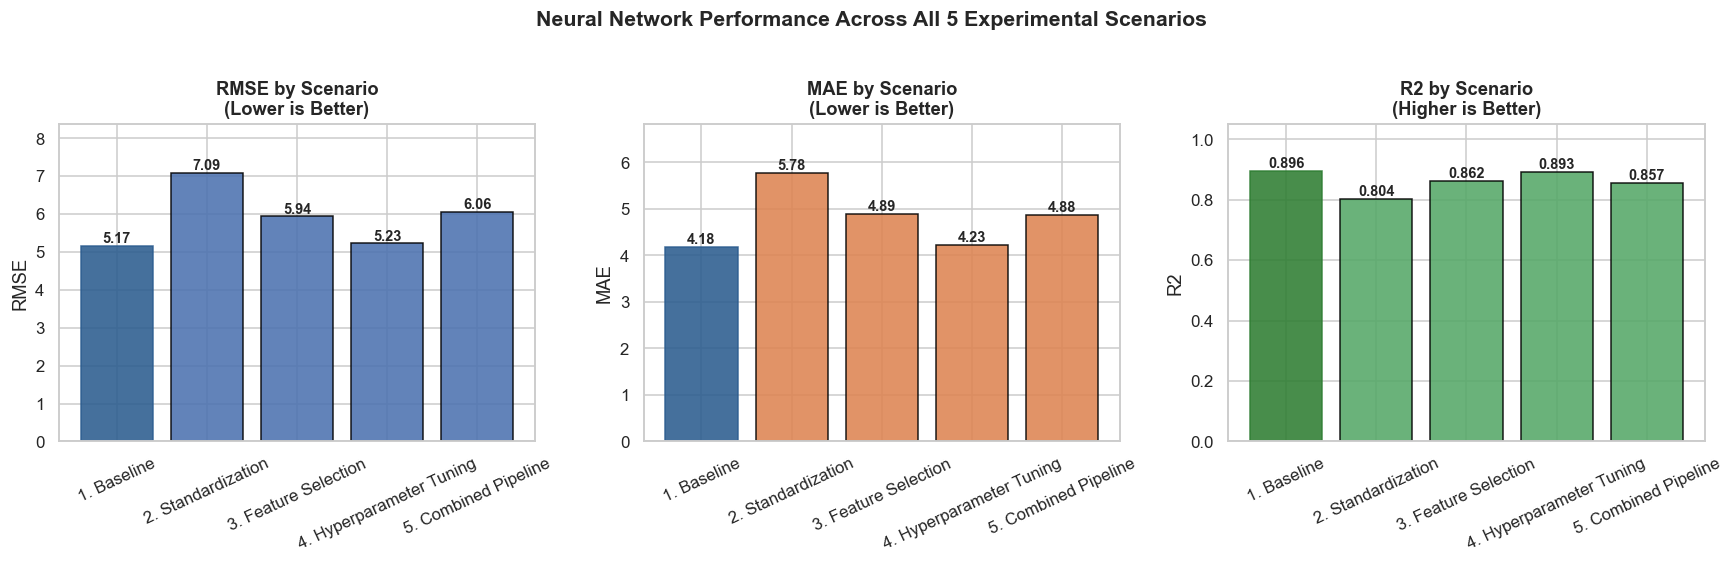

In [15]:
# Visualization 1: Side-by-side metric comparison across all 5 scenarios
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = [("RMSE", "Lower is Better", "#4c72b0"),
           ("MAE", "Lower is Better", "#dd8452"),
           ("R2", "Higher is Better", "#55a868")]

for ax, (metric, subtitle, color) in zip(axes, metrics):
    bars = ax.bar(results_df["Scenario"], results_df[metric], color=color, edgecolor="black", alpha=0.88)
    ax.set_title(f"{metric} by Scenario\n({subtitle})", fontsize=12, fontweight="bold")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylabel(metric)

    # Highlight best bar
    best_bar_idx = results_df[metric].idxmax() if metric == "R2" else results_df[metric].idxmin()
    bars[best_bar_idx].set_color("#2b5c8f" if metric != "R2" else "#2e7d32")

    for bar in bars:
        val = bar.get_height()
        fmt = f"{val:.3f}" if metric == "R2" else f"{val:.2f}"
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            val,
            fmt,
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold",
        )

    if metric == "R2":
        ax.set_ylim(0, 1.05)
    else:
        ax.set_ylim(0, results_df[metric].max() * 1.18)

plt.suptitle("Neural Network Performance Across All 5 Experimental Scenarios", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

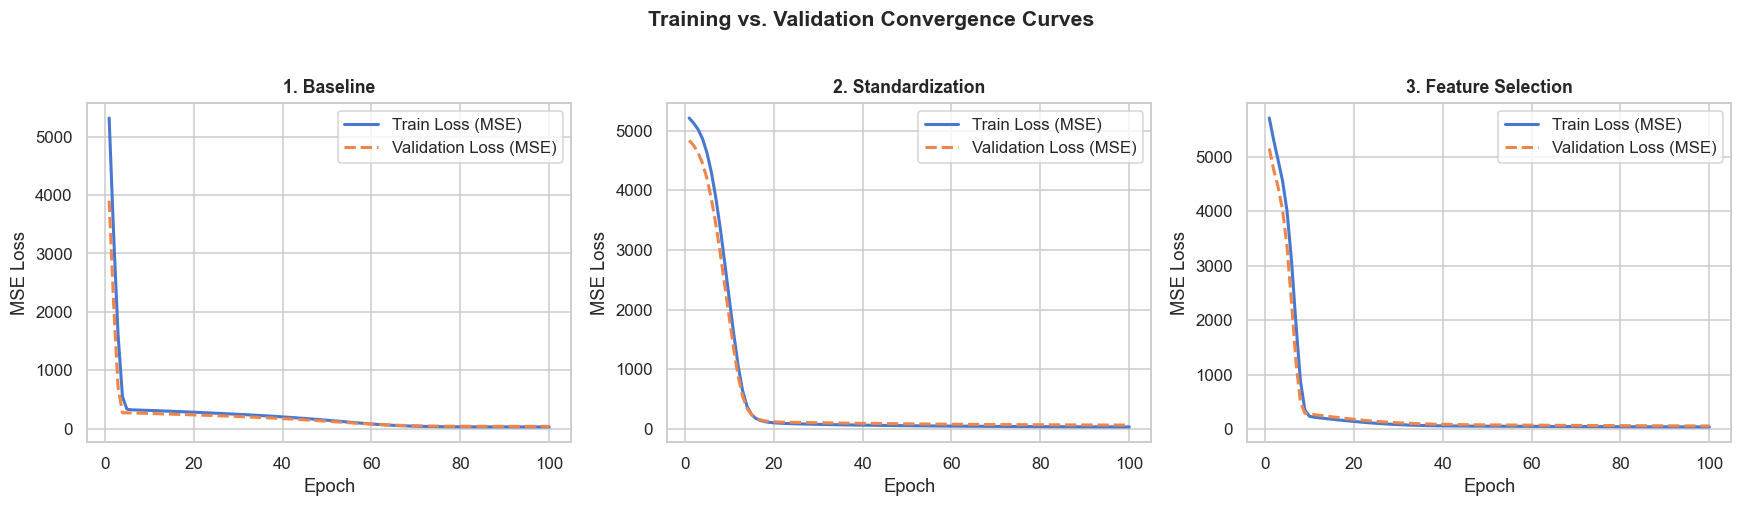

In [16]:
# Visualization 2: Training vs. Validation Loss Curves (Scenarios 1–3)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)

for ax, (name, hist) in zip(axes, histories_log.items()):
    epochs_range = range(1, len(hist["loss"]) + 1)
    ax.plot(epochs_range, hist["loss"], label="Train Loss (MSE)", linewidth=2)
    ax.plot(epochs_range, hist["val_loss"], label="Validation Loss (MSE)", linewidth=2, linestyle="--")
    ax.set_title(name, fontsize=11.5, fontweight="bold")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE Loss")
    ax.legend()

plt.suptitle("Training vs. Validation Convergence Curves", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

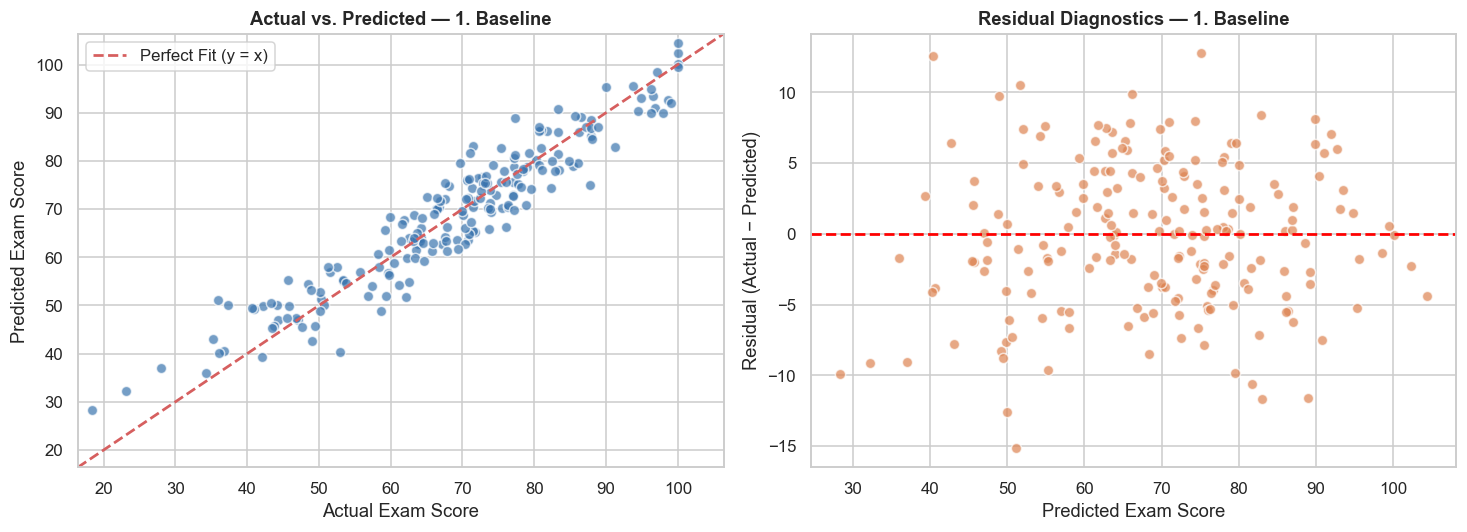

In [17]:
# Visualization 3: Actual vs. Predicted & Residual Plot for the Best Model
y_pred_best = predictions_log[best_scenario_name]
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5))

# Left: Actual vs. Predicted
axes[0].scatter(y_test, y_pred_best, alpha=0.7, color="#3b75af", edgecolor="white", s=45)
lims = [min(y_test.min(), y_pred_best.min()) - 2, max(y_test.max(), y_pred_best.max()) + 2]
axes[0].plot(lims, lims, "r--", linewidth=1.8, label="Perfect Fit (y = x)")
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_title(f"Actual vs. Predicted — {best_scenario_name}", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Actual Exam Score")
axes[0].set_ylabel("Predicted Exam Score")
axes[0].legend()

# Right: Residuals vs. Predicted
axes[1].scatter(y_pred_best, residuals, alpha=0.7, color="#dd8452", edgecolor="white", s=45)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.8)
axes[1].set_title(f"Residual Diagnostics — {best_scenario_name}", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Exam Score")
axes[1].set_ylabel("Residual (Actual − Predicted)")

plt.tight_layout()
plt.show()

## 7. Key Findings, Limitations & Next Steps

### Key Findings
* **Controlled Benchmarking Matters:** Evaluating all five scenarios on a single shared train–test split (`random_state=42`) with leakage-free scaling provides a fair comparison of preprocessing and tuning choices.
* **Feature Breadth vs. Pruning:** While `study_hours_per_day` and `mental_health_rating` explain the bulk of variance in `exam_score`, secondary habits such as `sleep_hours` and `attendance_percentage` still contribute useful signal—so aggressive pruning to only 5 features can trade away accuracy compared to retaining the full feature set.
* **Hyperparameter Sensitivity:** Learning rate (`0.001` vs. `0.01`) and batch size (`16` vs. `32`) significantly affect convergence speed and generalization on small tabular datasets when training for 50–100 epochs.

### Limitations
* **Dataset Size:** With 1,000 samples, neural networks are sensitive to initialization and epoch budgets; small tabular datasets often benefit from simpler linear or tree-based models.
* **Target Ceiling Effect:** Because `exam_score` is capped at `100.0`, unconstrained linear output layers can occasionally predict values slightly above `100` for high-performing students.

### Recommended Next Steps
1. **Cross-Model Baseline:** Benchmark the best MLP against **Ridge Regression**, **Random Forest**, and **XGBoost / LightGBM** on the same split.
2. **Early Stopping & Regularization:** Add `EarlyStopping(restore_best_weights=True)` and test `Dropout` / L2 weight decay to prevent overfitting.
3. **Interactive Inference Demo:** Export the winning pipeline and wrap it in a lightweight Streamlit or FastAPI app where users can adjust daily habits to simulate predicted exam scores.